/tmp/ipykernel_1679/3981562916.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


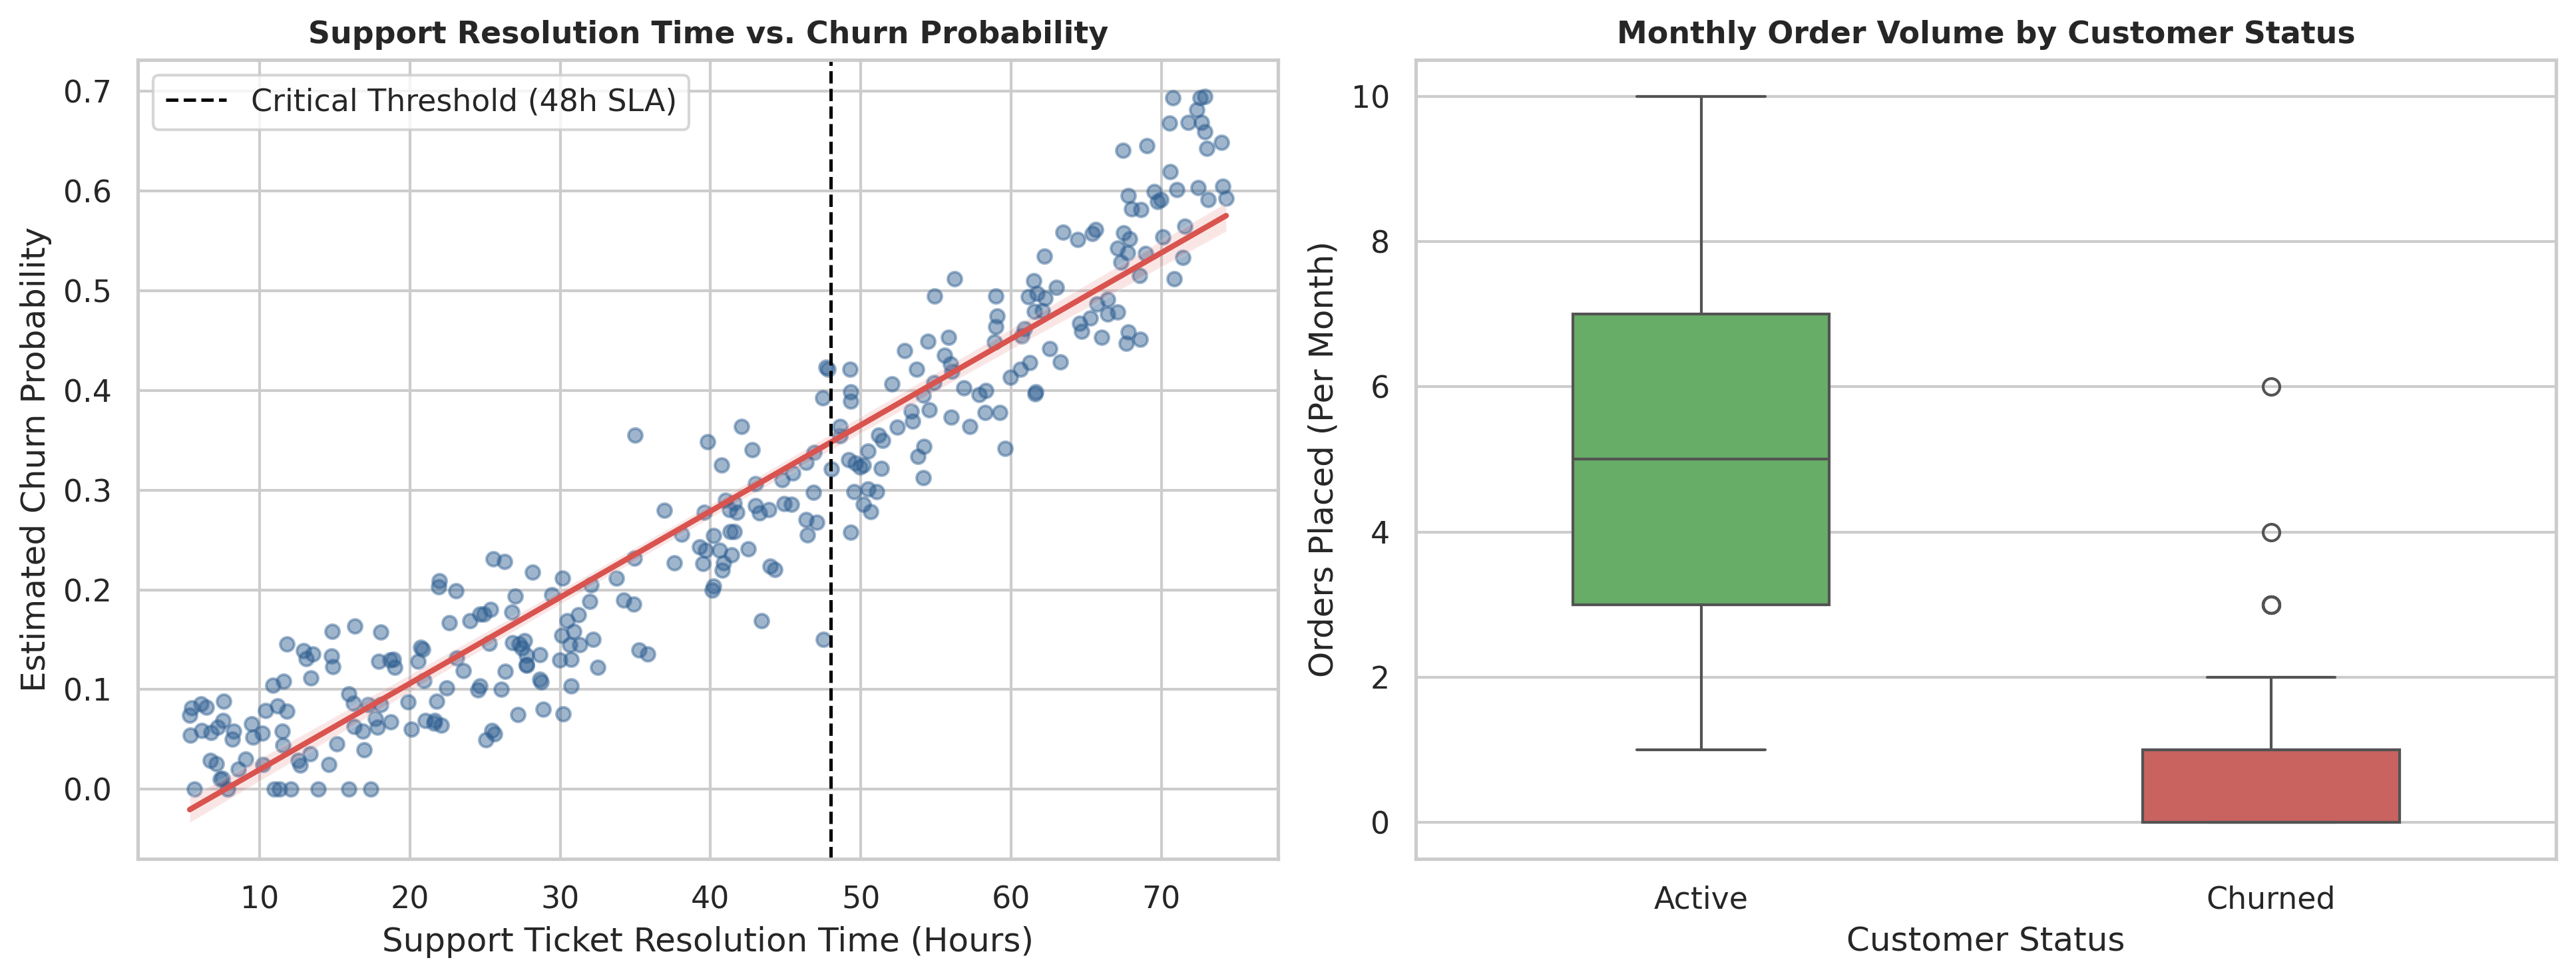

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configure clean aesthetic settings
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

# Generate representative dataset for the business case
np.random.seed(42)
n_records = 300

resolution_hours = np.random.uniform(5, 75, n_records)
# Churn risk increases significantly after 48 hours
base_risk = 0.05 + (resolution_hours / 100) ** 1.8
churn_risk = np.clip(base_risk + np.random.normal(0, 0.05, n_records), 0, 1)

account_status = np.where(churn_risk > 0.35, "Churned", "Active")
monthly_orders = np.where(
    account_status == "Active",
    np.random.poisson(lam=5, size=n_records),
    np.random.poisson(lam=1, size=n_records),
)

df = pd.DataFrame(
    {
        "resolution_hours": resolution_hours,
        "churn_risk": churn_risk,
        "monthly_orders": monthly_orders,
        "account_status": account_status,
    }
)

# Create 2-panel executive figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# Panel 1: Regression Analysis with 48h SLA Benchmark
sns.regplot(
    data=df,
    x="resolution_hours",
    y="churn_risk",
    ax=ax1,
    color="#2b5c8f",
    scatter_kws={"alpha": 0.45, "s": 25},
    line_kws={"color": "#d9534f", "linewidth": 2},
)
ax1.axvline(
    x=48,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Critical Threshold (48h SLA)",
)
ax1.set_title(
    "Support Resolution Time vs. Churn Probability",
    fontsize=11,
    fontweight="bold",
)
ax1.set_xlabel("Support Ticket Resolution Time (Hours)")
ax1.set_ylabel("Estimated Churn Probability")
ax1.legend(loc="upper left")

# Panel 2: Distribution Comparison
sns.boxplot(
    data=df,
    x="account_status",
    y="monthly_orders",
    ax=ax2,
    palette=["#5cb85c", "#d9534f"],
    width=0.45,
)
ax2.set_title(
    "Monthly Order Volume by Customer Status", fontsize=11, fontweight="bold"
)
ax2.set_xlabel("Customer Status")
ax2.set_ylabel("Orders Placed (Per Month)")

# Save high-resolution figure for report inclusion
plt.savefig("executive_churn_analysis.png", dpi=300)
plt.show()